In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import *
import matplotlib.font_manager
import matplotlib.patheffects as path_effects
from matplotlib.colors import LinearSegmentedColormap

In [2]:
df = pd.read_csv(r'../../TEMPLATE_PROJECTS/BHA_2425_Premier.csv')
df.shape

(40930, 268)

In [3]:
font_names = [f.name for f in matplotlib.font_manager.fontManager.ttflist]
print(*font_names, sep='||')

STIXGeneral||cmex10||DejaVu Sans||DejaVu Sans Mono||cmb10||STIXSizeThreeSym||DejaVu Sans Mono||DejaVu Serif||cmss10||DejaVu Sans Mono||STIXSizeFourSym||cmr10||DejaVu Sans Display||STIXNonUnicode||cmmi10||cmtt10||STIXGeneral||DejaVu Sans Mono||DejaVu Serif Display||DejaVu Sans||STIXSizeFourSym||DejaVu Sans||STIXNonUnicode||STIXSizeOneSym||STIXSizeFiveSym||STIXSizeTwoSym||DejaVu Serif||STIXNonUnicode||STIXSizeTwoSym||STIXSizeOneSym||DejaVu Serif||DejaVu Serif||STIXNonUnicode||STIXGeneral||STIXGeneral||cmsy10||DejaVu Sans||STIXSizeThreeSym||Bodoni MT||Palatino Linotype||Franklin Gothic Book||Rockwell Condensed||Corbel||Algerian||Agency FB||Calibri||Lucida Calligraphy||Segoe UI||Lucida Sans Typewriter||Lucida Sans Typewriter||Perpetua||Sylfaen||Tw Cen MT||SimSun-ExtB||Wingdings 2||Microsoft YaHei||Lucida Sans||MV Boli||Webdings||Haettenschweiler||Malgun Gothic||Century Schoolbook||MT Extra||Sitka||Trebuchet MS||Calibri||Perpetua Titling MT||Bookman Old Style||Lucida Fax||Eras Light ITC||Be

In [4]:
df.head(2)

,index,eventId,minute,second,teamId,x,y,period,type,outcomeType,...,type_value_SecondYellow,type_value_ThirtyFivePlusCentre,value_FromShotOffTarget,value_VoidYellowCard,value_SecondYellow,value_ThirtyFivePlusCentre,type_value_OutOfBoxLeft,value_OutOfBoxLeft,type_value_OutOfBoxDeepLeft,value_OutOfBoxDeepLeft
0,1,4.0,0,0.0,31,52.71,33.796,FirstHalf,Pass,Successful,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,5.0,0,2.0,31,25.41,29.308,FirstHalf,Pass,Unsuccessful,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
#CHECK PITCH DIMENSIONS BY GETTING MAX X & Y COORDS
pitch_length = df['x'].max()
pitch_width = df['y'].max()

str(pitch_length) + " & " + str(pitch_width)

#str(df['x'].max()) + " & " + str(df['y'].max())


'105.0 & 68.0'

In [6]:
df['name'].str.contains('Hecke')

0        False
1        False
2        False
3        False
4        False
         ...  
40925    False
40926    False
40927    False
40928      NaN
40929      NaN
Name: name, Length: 40930, dtype: object

In [7]:
team_mask = (df['teamName'].str.contains('Brighton', case=True, na=False))
player_mask = ((df['name'].str.contains('van Hecke', case=True, na=False)))
df_hecke = df[team_mask & player_mask].copy().reset_index(drop=False)
van_hecke = df_hecke['name'][0]
df_hecke['type'].value_counts()

type
Pass               1440
Carry               685
Clearance            91
Aerial               84
BallTouch            33
Foul                 31
Tackle               28
Save                 13
CornerAwarded        13
Challenge            11
Interception         10
TakeOn                8
BlockedPass           7
Dispossessed          5
Card                  5
MissedShots           4
SavedShot             4
Goal                  1
Error                 1
ShotOnPost            1
SubstitutionOff       1
OffsidePass           1
Name: count, dtype: int64

In [8]:
passes_into_opp_half_mask = ((df_hecke['type'] == 'Pass') & (df_hecke['x'] <= (pitch_length/2)) & (df_hecke['endX'] >= (pitch_length/2)) & (df_hecke['outcomeType'] == 'Successful'))
df_passes = df_hecke[passes_into_opp_half_mask]
df_passes.shape[0]

179

In [9]:
pitch = Pitch(pitch_type='uefa')

df_temp = df_hecke[(df_hecke['type'] == 'Pass')& (df_hecke['endX'] >= (pitch.dim.length / 3)*2)]
succ_last_third_passes_count = (df_temp[df_temp['outcomeType'] == 'Successful']).shape[0]
unsucc_last_third_passes_count = (df_temp[df_temp['outcomeType'] != 'Successful']).shape[0]
total_last_third_passes_count = succ_last_third_passes_count + unsucc_last_third_passes_count
last_third_pass_ratio = (succ_last_third_passes_count / total_last_third_passes_count)
last_third_pass_ratio = f"{last_third_pass_ratio:.2%}"


df_temp = df_hecke[(df_hecke['x'] <= (pitch_length/2)) & (df_hecke['endX'] >= (pitch_length/2))]
succ_fwd_passes_count = (df_temp[df_temp['outcomeType'] == 'Successful']).shape[0]
unsucc_fwd_passes_count = (df_temp[df_temp['outcomeType'] != 'Successful']).shape[0]
total_fwd_passes_count = succ_fwd_passes_count + unsucc_fwd_passes_count
fwd_pass_ratio = (succ_fwd_passes_count / total_fwd_passes_count)
fwd_pass_ratio = f"{fwd_pass_ratio:.2%}"


df_temp = df_hecke[df_hecke['type'] == 'Pass']
succ_passes_count = (df_temp[df_temp['outcomeType'] == 'Successful']).shape[0]
unsucc_passes_count = (df_temp[df_temp['outcomeType'] != 'Successful']).shape[0]
total_passes_count = succ_passes_count + unsucc_passes_count
pass_ratio = (succ_passes_count / total_passes_count)
pass_ratio = f"{pass_ratio:.2%}"

"Pass: " + str(pass_ratio) + " | Fwd pass: " + str(fwd_pass_ratio) + " | 1/3 pass: " + str(last_third_pass_ratio)

'Pass: 87.85% | Fwd pass: 77.71% | 1/3 pass: 71.75%'

Text(0.5, 1.0, 'Passes from own half into opp. half')

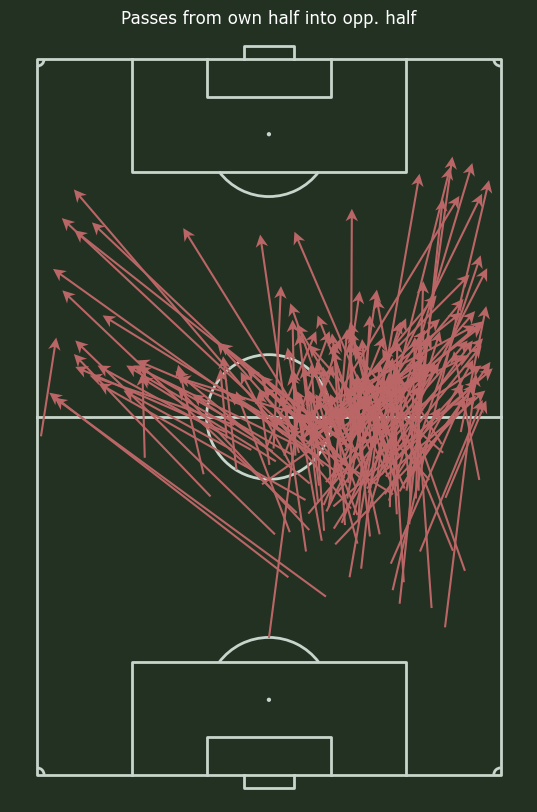

In [10]:
pitch = VerticalPitch(pitch_type='uefa', pitch_color='#223122', line_color='#C7D5CC', corner_arcs=True, goal_linestyle='solid', goal_type='box')
fig, ax = pitch.draw(figsize=(16, 10), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#223122')

pitch.arrows(xstart=df_passes['x'], xend=df_passes['endX'], ystart=df_passes['y'], yend=df_passes['endY'], ax=ax, color="#BB6666", width=1.5,
             headwidth=6, headlength=6, label=van_hecke)

plt.title("Passes from own half into opp. half", color='#FFFFFF', font='Verdana', fontsize=12)


In [11]:
forward_passes_mask = (df_hecke['x'] < df_hecke['endX'])
df_fwd_passes = df_hecke[forward_passes_mask]
df_fwd_passes.shape[0]

1716

In [12]:
# see the custom colormaps example for more ideas on setting colormaps
pearl_earring_cmap = LinearSegmentedColormap.from_list("El Greco Violet - 10 colors",
                                                       ["#0f466b", "#1f92df"], N=10)

# fontmanager for google font (robotto)
robotto_regular = FontManager()

path_eff = [path_effects.Stroke(linewidth=3, foreground='black'),
            path_effects.Normal()]

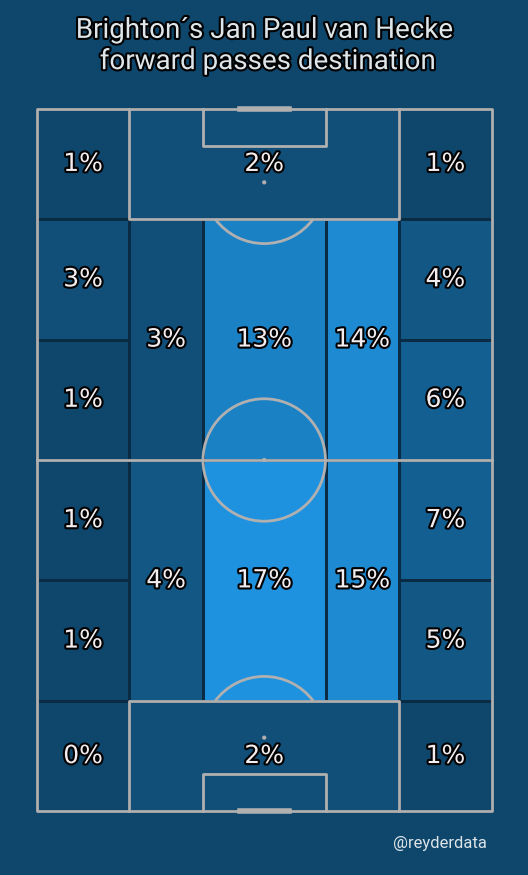

In [13]:
pitch = VerticalPitch(pitch_type='uefa', line_zorder=2, pitch_color='#0f466b')
fig, axs = pitch.grid(endnote_height=0.03, endnote_space=0,
                      title_height=0.08, title_space=0,
                      # Turn off the endnote/title axis. I usually do this after
                      # I am happy with the chart layout and text placement
                      axis=False,
                      grid_height=0.84)
fig.set_facecolor('#0f466b')

# heatmap and labels
bin_statistic = pitch.bin_statistic_positional(df_fwd_passes['endX'], df_fwd_passes['endY'], statistic='count',
                                               positional='full', normalize=True)
pitch.heatmap_positional(bin_statistic, ax=axs['pitch'],
                         cmap=pearl_earring_cmap, edgecolors="#092c44")
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=18,
                             ax=axs['pitch'], ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)


# endnote and title
axs['endnote'].text(.99, 0.8, '@reyderdata', va='center', ha='right', fontsize=12,
                    fontproperties=robotto_regular.prop, color='#dee6ea')
axs['title'].text(0.5, 0.5, f"{df_hecke['teamName'][0]}´s {van_hecke}\n forward passes destination", color='#dee6ea',
                  va='center', ha='center', path_effects=path_eff,
                  fontproperties=robotto_regular.prop, fontsize=20)
# sphinx_gallery_thumbnail_path = 'gallery/pitch_plots/images/sphx_glr_plot_heatmap_positional_002.png'

plt.tight_layout()
plt.show()  # If you are using a Jupyter notebook you do not need this line

In [14]:
risky_fwd_passes_mask = ((df_passes['x'] >= pitch.dim.penalty_area_bottom) & ((df_passes['endX'] >= (pitch.dim.length / 3)*2)))

df_fwd_passes_2 = df_passes[risky_fwd_passes_mask]

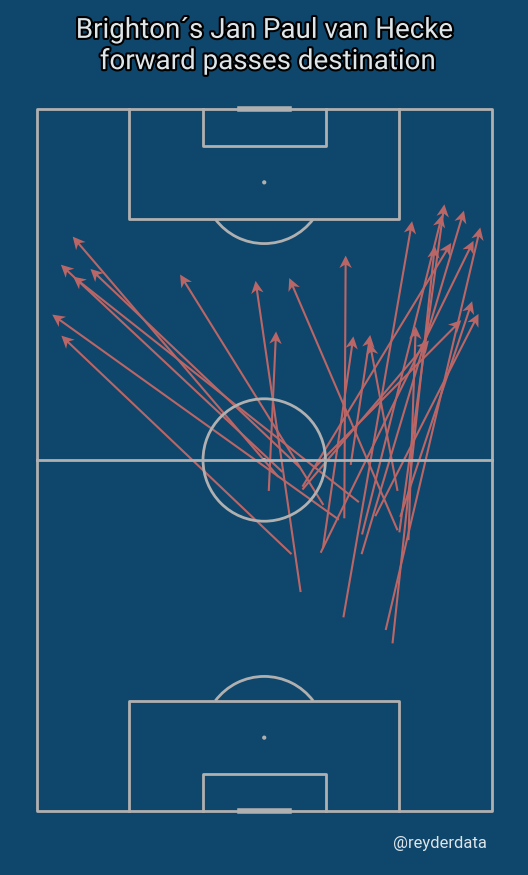

In [15]:
pitch = VerticalPitch(pitch_type='uefa', line_zorder=2, pitch_color='#0f466b')
fig, axs = pitch.grid(endnote_height=0.03, endnote_space=0,
                      title_height=0.08, title_space=0,
                      # Turn off the endnote/title axis. I usually do this after
                      # I am happy with the chart layout and text placement
                      axis=False,
                      grid_height=0.84)
fig.set_facecolor('#0f466b')

pitch.arrows(xstart=df_fwd_passes_2['x'], xend=df_fwd_passes_2['endX'], ystart=df_fwd_passes_2['y'], yend=df_fwd_passes_2['endY'], ax=axs['pitch'], color="#BB6666", width=1.5,
             headwidth=6, headlength=6, label=van_hecke)

# endnote and title
axs['endnote'].text(.99, 0.8, '@reyderdata', va='center', ha='right', fontsize=12,
                    fontproperties=robotto_regular.prop, color='#dee6ea')
axs['title'].text(0.5, 0.5, f"{df_hecke['teamName'][0]}´s {van_hecke}\n forward passes destination", color='#dee6ea',
                  va='center', ha='center', path_effects=path_eff,
                  fontproperties=robotto_regular.prop, fontsize=20)
# sphinx_gallery_thumbnail_path = 'gallery/pitch_plots/images/sphx_glr_plot_heatmap_positional_002.png'

plt.tight_layout()
plt.show()  # If you are using a Jupyter notebook you do not need this line

In [16]:
df_passes = df_hecke[(df_hecke['type'] == 'Pass') & (df_hecke['outcomeType'] == 'Successful')]

df_fwd_passes = df_passes[(df_passes['x'] < df_passes['endX'])]

df_last_third_passes = df_fwd_passes[(df_fwd_passes['endX'] >= (pitch.dim.length / 3)*2)]

In [17]:
pearl_earring_cmap_100 = LinearSegmentedColormap.from_list("Pearl Earring - 100 colors",
                                                           ["#0c2435", "#4eade9"], N=200)

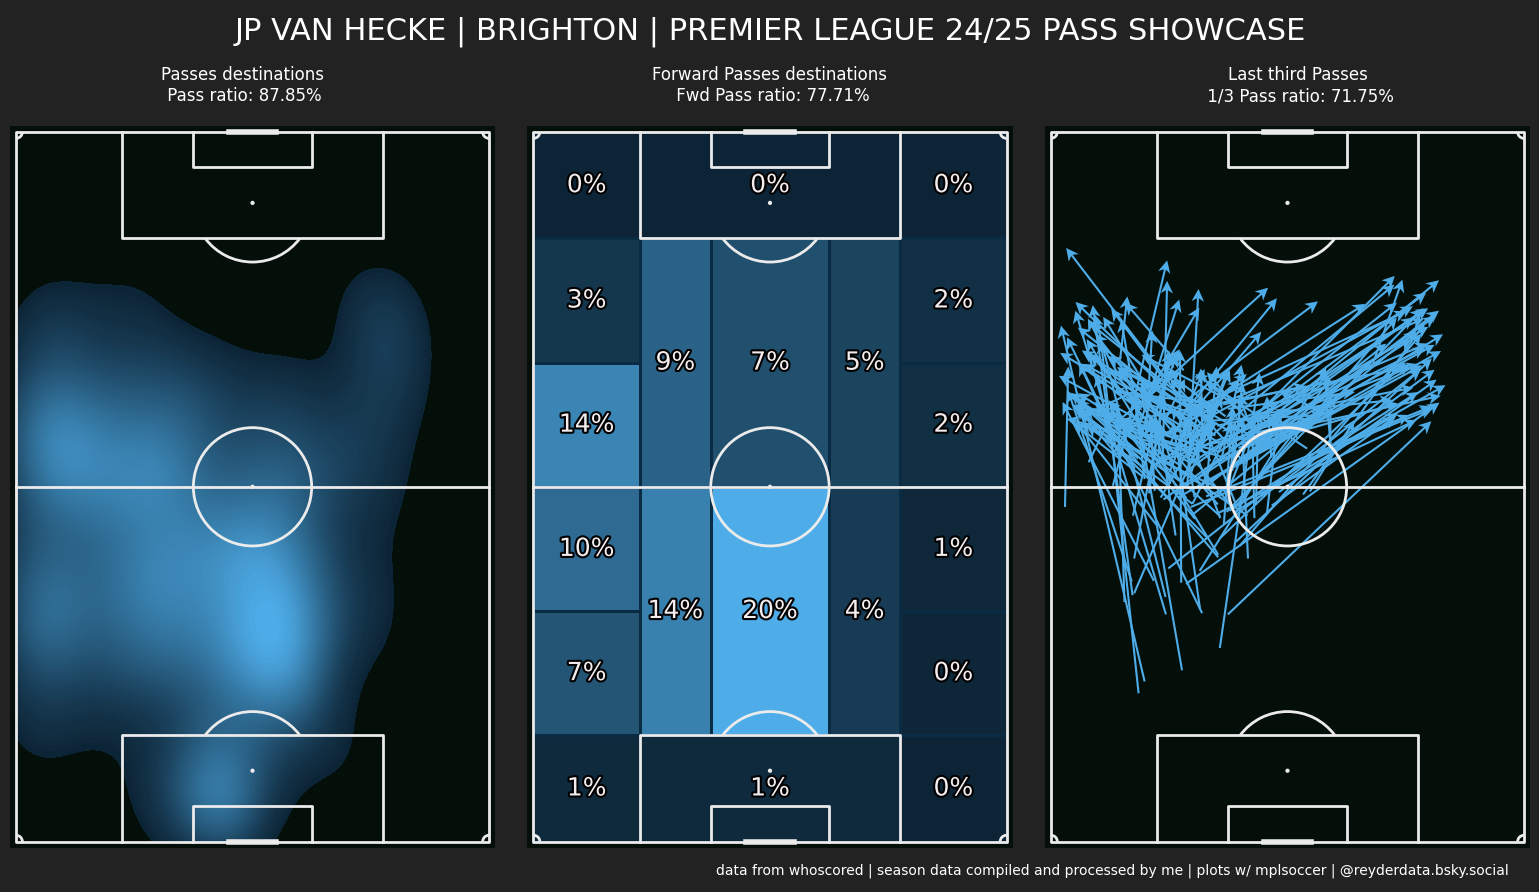

In [19]:
FIGWIDTH = 16
FIGHEIGHT = 9
NROWS = 1
NCOLS = 3
SPACE = 0.09
MAX_GRID = 0.95
BG_COLOR = "#222222"
TEXT_FIRST_COL=f"Passes destinations\n Pass ratio: {pass_ratio}"
TEXT_SECOND_COL=f"Forward Passes destinations\n Fwd Pass ratio: {fwd_pass_ratio}"
TEXT_THIRD_COL=f"Last third Passes\n 1/3 Pass ratio: {last_third_pass_ratio}"

pitch = VerticalPitch(pad_top=1, pad_bottom=1, pad_left=1, pad_right=1, pitch_color="#040F0A", line_color="#EBEBEB", corner_arcs=True, spot_type='circle', line_zorder=2)

GRID_WIDTH, GRID_HEIGHT = pitch.grid_dimensions(figwidth=FIGWIDTH, figheight=FIGHEIGHT, nrows=NROWS, ncols=NCOLS, max_grid=MAX_GRID, space=SPACE)

TITLE_HEIGHT = 0.12
ENDNOTE_HEIGHT = MAX_GRID - (GRID_HEIGHT + TITLE_HEIGHT)

#axis=False when all objects are setted up
fig, axs = pitch.grid(figheight=FIGHEIGHT, grid_width=GRID_WIDTH, grid_height=GRID_HEIGHT, space=SPACE, ncols=NCOLS, nrows=NROWS, title_height=TITLE_HEIGHT, endnote_height = ENDNOTE_HEIGHT, axis=False)

ax1 = axs['pitch'][0]
ax2 = axs['pitch'][1]
ax3 = axs['pitch'][2]

pitch1 = pitch.kdeplot(df_passes['endX'], df_passes['endY'], ax=ax1 ,cmap=pearl_earring_cmap_100, fill=True, levels=100)

# heatmap and labels
bin_statistic = pitch.bin_statistic_positional(df_fwd_passes['endX'], df_fwd_passes['endY'], statistic='count',
                                               positional='full', normalize=True)
pitch2 = pitch.heatmap_positional(bin_statistic, ax=ax2, cmap=pearl_earring_cmap_100, edgecolors="#092c44")
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=18,
                             ax=ax2, ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)

pitch3 = pitch.arrows(xstart=df_last_third_passes['x'], xend=df_last_third_passes['endX'], ystart=df_last_third_passes['y'], yend=df_last_third_passes['endY'], ax=ax3, color="#4eade9", width=1.5,
             headwidth=6, headlength=6, label=van_hecke)


fig.set_facecolor(BG_COLOR)
axs['title'].set_facecolor('None')
axs['endnote'].set_facecolor('None')

axs['title'].text(.5, .8, "JP VAN HECKE | BRIGHTON | PREMIER LEAGUE 24/25 PASS SHOWCASE", fontsize=22, va='center', ha='center', color='#FFFFFF')
axs['title'].text(.15, .3, TEXT_FIRST_COL, fontsize=12, va='center', ha='center', color='#FFFFFF')
axs['title'].text(.5, .3, TEXT_SECOND_COL, fontsize=12, va='center', ha='center', color='#FFFFFF')
axs['title'].text(.85, .3, TEXT_THIRD_COL, fontsize=12, va='center', ha='center', color='#FFFFFF')

axs['endnote'].text(.99, .5, "data from whoscored | season data compiled and processed by me | plots w/ mplsoccer | @reyderdata.bsky.social", fontsize=10, va='center', ha='right', color='#FFFFFF')

fig.savefig("van_hecke_pass_plots.png", dpi=300, bbox_inches='tight')